# Clustering Urban Mobility Patterns Using Bike-Sharing Data
**Dataset:** UCI Bike Sharing Dataset (`hour.csv`) — Capital Bikeshare, Washington, D.C.

**Clustering unit:** one row per **day** (hourly records are aggregated into daily feature vectors).

This notebook is organised to follow the assignment structure:
- Part 1 — Data Preparation and Feature Engineering *(this notebook, so far)*
- Part 2 — Clustering (K-Means, AGNES, DBSCAN) *(not yet implemented)*
- Part 3 — Evaluation and Comparison *(not yet implemented)*
- Part 4 — Cluster Interpretation and Validation *(not yet implemented)*
- Part 5 — Theoretical Questions *(answered separately in the report)*

## Setup: Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics.pairwise import euclidean_distances

## Part 1.1 — Inspect and Clean the Data
Load the hourly dataset and get a first look at its shape, columns and sample records before checking for missing values, duplicates and formatting issues.

### Load the raw hourly dataset

In [2]:
df = pd.read_csv("../bike+sharing+dataset/hour.csv")

### Initial inspection: shape, sample rows, column names

In [3]:
df.shape

(17379, 17)

In [4]:
df.head(10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


In [5]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

### Check for missing values
A heatmap gives a quick visual scan across all columns, and the exact per-column null counts confirm whether any imputation or row removal is required.

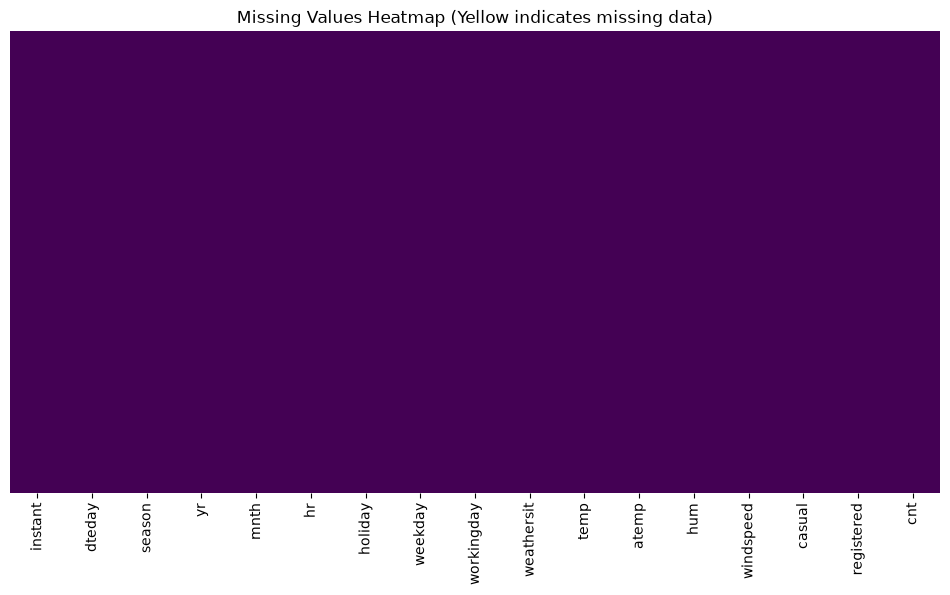

Exact count of null values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [6]:
# Visualize missing values using a Seaborn heatmap
plt.figure(figsize=(12, 6))
# cbar=False hides the colorbar, yticklabels=False hides the row numbers for a cleaner look
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Heatmap (Yellow indicates missing data)')
plt.show()

# Print the exact numerical count of nulls per column for verification
print("Exact count of null values per column:")
print(df.isnull().sum())

### Check for duplicate records

In [7]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


### Convert the date column to a proper datetime format
`dteday` is read from the CSV as a string, so it is converted to `datetime64` to allow date-based grouping and calendar-feature extraction later on.

In [8]:
df['dteday'] = pd.to_datetime(df['dteday'])
print(df.dtypes['dteday'])

datetime64[us]


### Verify each date has a reasonable number of hourly observations
Since the clustering unit is a **day**, each date should ideally have 24 hourly records. Counting records per day surfaces any days with missing hours (e.g. due to system outages).

In [9]:
hours_per_day = df.groupby('dteday')['hr'].count()

# Look at the distribution of hours per day
print("Distribution of hourly records per day:")
print(hours_per_day.value_counts())

Distribution of hourly records per day:
hr
24    655
23     62
22      6
18      2
12      1
16      1
8       1
17      1
1       1
11      1
Name: count, dtype: int64


In [10]:
incomplete_days = hours_per_day[hours_per_day < 24]
print("\nIncomplete days and their record counts:")
print(incomplete_days)


Incomplete days and their record counts:
dteday
2011-01-02    23
2011-01-03    22
2011-01-04    23
2011-01-05    23
2011-01-06    23
              ..
2012-10-30    11
2012-11-08    23
2012-11-29    23
2012-12-24    23
2012-12-25    23
Name: hr, Length: 76, dtype: int64


### Handle incomplete days
**Decision:** days with fewer than **22** hourly records are dropped before feature aggregation. Days close to the full 24 hours (22–24) are kept as-is, since a couple of missing hours has minimal effect on daily aggregates, whereas days with substantially fewer hours would produce unreliable/biased daily statistics (e.g. an artificially low `total_rentals` or skewed peak-share ratios).

In [11]:
# 1. Count the number of hourly records per day
hours_per_day = df.groupby('dteday')['hr'].count()

# 2. Define a threshold (e.g., keep days with 22 or more hours)
valid_days = hours_per_day[hours_per_day >= 22].index

# 3. Filter the original dataframe to only include records from valid days
df_clean = df[df['dteday'].isin(valid_days)]

## Part 1.2 — Generate Daily Mobility Features
The cleaned hourly records (`df_clean`) are aggregated by date into a daily feature vector. Features are built up in stages: core daily statistics, time-of-day rental shares, user-type shares, and calendar context.

### Flag rentals in the morning-peak and evening-peak windows
Morning peak = 06:00–09:00, Evening peak = 16:00–19:00 (per the assignment spec). Each hourly row is tagged with its rental count if it falls in that window, else 0, so these can be summed per day in the next step.

In [12]:
df_clean['morning_rentals'] = df_clean.apply(
    lambda row: row['cnt'] if 6 <= row['hr'] <= 9 else 0, axis=1
)

# Evening peak: 4:00 p.m. to 7:00 p.m. (hours 16, 17, 18, 19)
df_clean['evening_rentals'] = df_clean.apply(
    lambda row: row['cnt'] if 16 <= row['hr'] <= 19 else 0, axis=1
)

### Aggregate core daily statistics
For each day: total, average, maximum and standard deviation of hourly rentals; total casual vs. registered riders; total morning/evening-peak rentals; and average weather conditions (temperature, humidity, windspeed).

In [13]:
# Aggregate the hourly records into a new daily dataframe
daily_features = df_clean.groupby('dteday').agg(
    total_rentals=('cnt', 'sum'),
    avg_hourly_rentals=('cnt', 'mean'),
    max_hourly_rentals=('cnt', 'max'),
    std_hourly_rentals=('cnt', 'std'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum'),
    total_morning=('morning_rentals', 'sum'),
    total_evening=('evening_rentals', 'sum'),
    avg_temp=('temp', 'mean'),
    avg_humidity=('hum', 'mean'),
    avg_windspeed=('windspeed', 'mean')
)

Quick check of the aggregated daily table:

In [14]:
daily_features.head()

,total_rentals,avg_hourly_rentals,max_hourly_rentals,std_hourly_rentals,total_casual,total_registered,total_morning,total_evening,avg_temp,avg_humidity,avg_windspeed
dteday,,,,,,,,,,,
2011-01-01,985,41.041667,110,34.292196,331,654,27,232,0.344167,0.805833,0.160446
2011-01-02,801,34.826087,93,29.785067,131,670,31,224,0.363478,0.696087,0.248539
2011-01-03,1349,61.318182,157,48.792453,120,1229,336,500,0.196364,0.437273,0.248309
2011-01-04,1562,67.913043,212,59.889985,108,1454,409,589,0.200000,0.590435,0.160296
2011-01-05,1600,69.565217,195,58.427753,82,1518,431,580,0.226957,0.436957,0.186900


### Additional time-of-day features (beyond the required minimum)
Midday (10:00–15:00) and night (23:00–05:00) rental flags are added to capture more of the daily rhythm than just the two peak windows — these support a richer characterisation of each day's demand profile.

In [15]:
# 1. Midday Rentals: 10:00 a.m. to 3:00 p.m. (hours 10 through 15)
df_clean['midday_rentals'] = np.where(
    (df_clean['hr'] >= 10) & (df_clean['hr'] <= 15), df_clean['cnt'], 0
)

# 2. Night Rentals: 11:00 p.m. to 5:00 a.m. (hours 23, and 0 through 5)
df_clean['night_rentals'] = np.where(
    (df_clean['hr'] >= 23) | (df_clean['hr'] <= 5), df_clean['cnt'], 0
)

### Aggregate the additional features, including peak hour
Totals for midday/night rentals are summed per day, and `peak_hour` records the specific hour with the highest rental count for that day.

In [16]:
# Group by date to get the daily totals and the peak hour
additional_aggs = df_clean.groupby('dteday').agg(
    total_midday=('midday_rentals', 'sum'),
    total_night=('night_rentals', 'sum'),
    # Find the index of the max value in 'cnt', then get the 'hr' for that index
    peak_hour=('cnt', lambda x: df_clean.loc[x.idxmax(), 'hr'])
)

# Merge these new columns into your existing daily_features dataframe
daily_features = daily_features.join(additional_aggs)

### Derive peak-share ratios and variability measures
- `morning_peak_share` / `evening_peak_share` — required features from the spec.
- `midday_share`, `night_share` — supporting proportions for the additional time windows.
- `morning_to_evening_ratio` — captures whether a day skews towards commute-in or commute-home demand (small epsilon added to avoid division by zero).
- `demand_cv` (coefficient of variation) — normalised measure of how spiky vs. flat a day's hourly demand is, independent of the day's overall volume.

In [17]:
# 1. Calculate all Shares (Proportions)
daily_features['midday_share'] = daily_features['total_midday'] / daily_features['total_rentals']
daily_features['night_share'] = daily_features['total_night'] / daily_features['total_rentals']

# Make sure the names match exactly what you use in the ratio below!
daily_features['morning_peak_share'] = daily_features['total_morning'] / daily_features['total_rentals']
daily_features['evening_peak_share'] = daily_features['total_evening'] / daily_features['total_rentals']

# 2. Morning-to-Evening Ratio
# Add 0.0001 to avoid a ZeroDivisionError just in case evening_peak_share is exactly 0
daily_features['morning_to_evening_ratio'] = (
    daily_features['morning_peak_share'] / (daily_features['evening_peak_share'] + 0.0001)
)

# 3. Coefficient of Variation (CV = Standard Deviation / Mean)
daily_features['demand_cv'] = (
    daily_features['std_hourly_rentals'] / daily_features['avg_hourly_rentals']
)

Check the columns generated so far:

In [18]:
daily_features.columns

Index(['total_rentals', 'avg_hourly_rentals', 'max_hourly_rentals',
       'std_hourly_rentals', 'total_casual', 'total_registered',
       'total_morning', 'total_evening', 'avg_temp', 'avg_humidity',
       'avg_windspeed', 'total_midday', 'total_night', 'peak_hour',
       'midday_share', 'night_share', 'morning_peak_share',
       'evening_peak_share', 'morning_to_evening_ratio', 'demand_cv'],
      dtype='str')

### Complete the required feature set: user-type and off-peak shares
`casual_share` and `registered_share` give the proportion of rentals from each user type (required by the spec). `off_peak_share` is the complement of the two peak shares, i.e. the proportion of a day's rentals that fall outside both the morning and evening peak windows.

In [19]:
# 1 & 2: Calculate user proportions
daily_features['casual_share'] = daily_features['total_casual'] / daily_features['total_rentals']
daily_features['registered_share'] = daily_features['total_registered'] / daily_features['total_rentals']

# 3: Calculate off-peak share (everything that isn't morning or evening peak)
daily_features['off_peak_share'] = 1.0 - (daily_features['morning_peak_share'] + daily_features['evening_peak_share'])

### Attach calendar context (not used for clustering itself)
`season`, `holiday`, `weekday` and `workingday` are kept alongside the daily feature table. They are **not** included in the clustering feature set (Part 1.3), but are retained here so they can be used later to interpret and validate the discovered clusters (Part 4), as permitted by the assignment.

In [20]:
calendar_features = df_clean.groupby('dteday').agg(
    season=('season', 'first'),
    holiday=('holiday', 'first'),
    weekday=('weekday', 'first'),
    workingday=('workingday', 'first')
)

daily_features = daily_features.join(calendar_features)

## Part 1.3 — Prepare the Clustering Data
Build the final numeric feature matrix that will actually be fed into K-Means, AGNES and DBSCAN, removing anything redundant or unsuitable for distance-based clustering.

**Features dropped and why:**
- `total_casual`, `total_registered`, `total_morning`, `total_evening`, `total_midday`, `total_night` — absolute counts that are already summarised (in relative/normalised form) by the corresponding *share* features; keeping both would double-count the same information and bias distance calculations toward high-volume days.
- `registered_share` — perfectly collinear with `casual_share` (`casual_share + registered_share = 1`), so only one is needed to avoid redundant, correlated dimensions.
- `off_peak_share` — linearly determined by `morning_peak_share` + `evening_peak_share` (their complement), so it carries no additional information for clustering distance once those two are present.
- `season`, `holiday`, `weekday`, `workingday` — categorical calendar variables, not part of the mobility-behaviour feature vector; reserved for cluster interpretation in Part 4 instead of being used as clustering inputs.

*Note: standardisation, skew checks, and correlation-driven feature removal from Part 1.3 are still to be finalised — see the correlation heatmap below as a first pass.*

In [21]:
features_to_drop_for_clustering = [
    'total_casual', 
    'total_registered', 
    'total_morning', 
    'total_evening',
    'total_midday',
    'total_night',
    'registered_share', 
    'off_peak_share',
    # Drop the calendar features from the clustering math
    'season', 
    'holiday', 
    'weekday', 
    'workingday'
]

# Create the clean dataframe specifically for K-Means/AGNES/DBSCAN
clustering_df = daily_features.drop(columns=features_to_drop_for_clustering)

# Verify it worked!
print("Clustering features:", clustering_df.columns.tolist())

Clustering features: ['total_rentals', 'avg_hourly_rentals', 'max_hourly_rentals', 'std_hourly_rentals', 'avg_temp', 'avg_humidity', 'avg_windspeed', 'peak_hour', 'midday_share', 'night_share', 'morning_peak_share', 'evening_peak_share', 'morning_to_evening_ratio', 'demand_cv', 'casual_share']


### 1.3.0 Investigating Highly Correlated and Redundant Features

Upon examining the correlation heatmap, several highly correlated features were identified. These were removed to prevent distortion in the distance calculations of our clustering algorithms.

* **Volume Metrics Overlap:** There is a highly correlated block among the raw volume metrics, specifically `total_rentals`, `avg_hourly_rentals`, `max_hourly_rentals`, and `std_hourly_rentals` (all showing correlation coefficients > **0.93**).
* **Action & Justification:** Distance-based algorithms (like K-Means and Hierarchical clustering) rely on the geometric distance between points. Including highly correlated features causes the algorithm to "double-count" that information, artificially overweighting the sheer volume of rentals compared to weather or time shares. To prevent this, `total_rentals`, `max_hourly_rentals`, and `std_hourly_rentals` were removed. `avg_hourly_rentals` was retained to represent the overall magnitude of demand, and the Coefficient of Variation (`demand_cv`) was kept because it captures volatility independently of total volume.


* **Morning Ratio Overlap:** The `morning_to_evening_ratio` feature showed a high correlation with `morning_peak_share` (**0.85**) and a strong negative correlation with `midday_share` (**-0.86**).
* **Action & Justification:** Because the ratio is mathematically derived from the morning and evening shares, retaining it introduces collinearity. The `morning_to_evening_ratio` was dropped, allowing the clustering algorithm to rely on the independent `morning_peak_share`, `evening_peak_share`, and `midday_share` metrics to evaluate the temporal shape of daily demand.

In [22]:
correlated_features_to_drop = [
    'total_rentals',             # Dropped in favor of avg_hourly_rentals
    'max_hourly_rentals',        # Redundant magnitude
    'std_hourly_rentals',        # Redundant magnitude (volatility captured by demand_cv)
    'morning_to_evening_ratio',   # Redundant with morning_peak_share
    'midday_share'
]

# Create your final, independent feature set
final_clustering_df = clustering_df.drop(columns=correlated_features_to_drop)

### 1.3.1 Examining Distributions and Handling Skewness

Before standardization, the distributions of all selected features were examined using histograms and mathematical skewness calculations. K-Means clustering performs best when features exhibit roughly symmetric, normal distributions, as extreme skewness can distort cluster centroids.

Any feature with a skewness score exceeding 1.0 was identified as highly right-skewed. To normalize these distributions and pull in long tails, a logarithmic transformation (`np.log1p`) was applied to these specific features before passing the dataset to the standardizer.

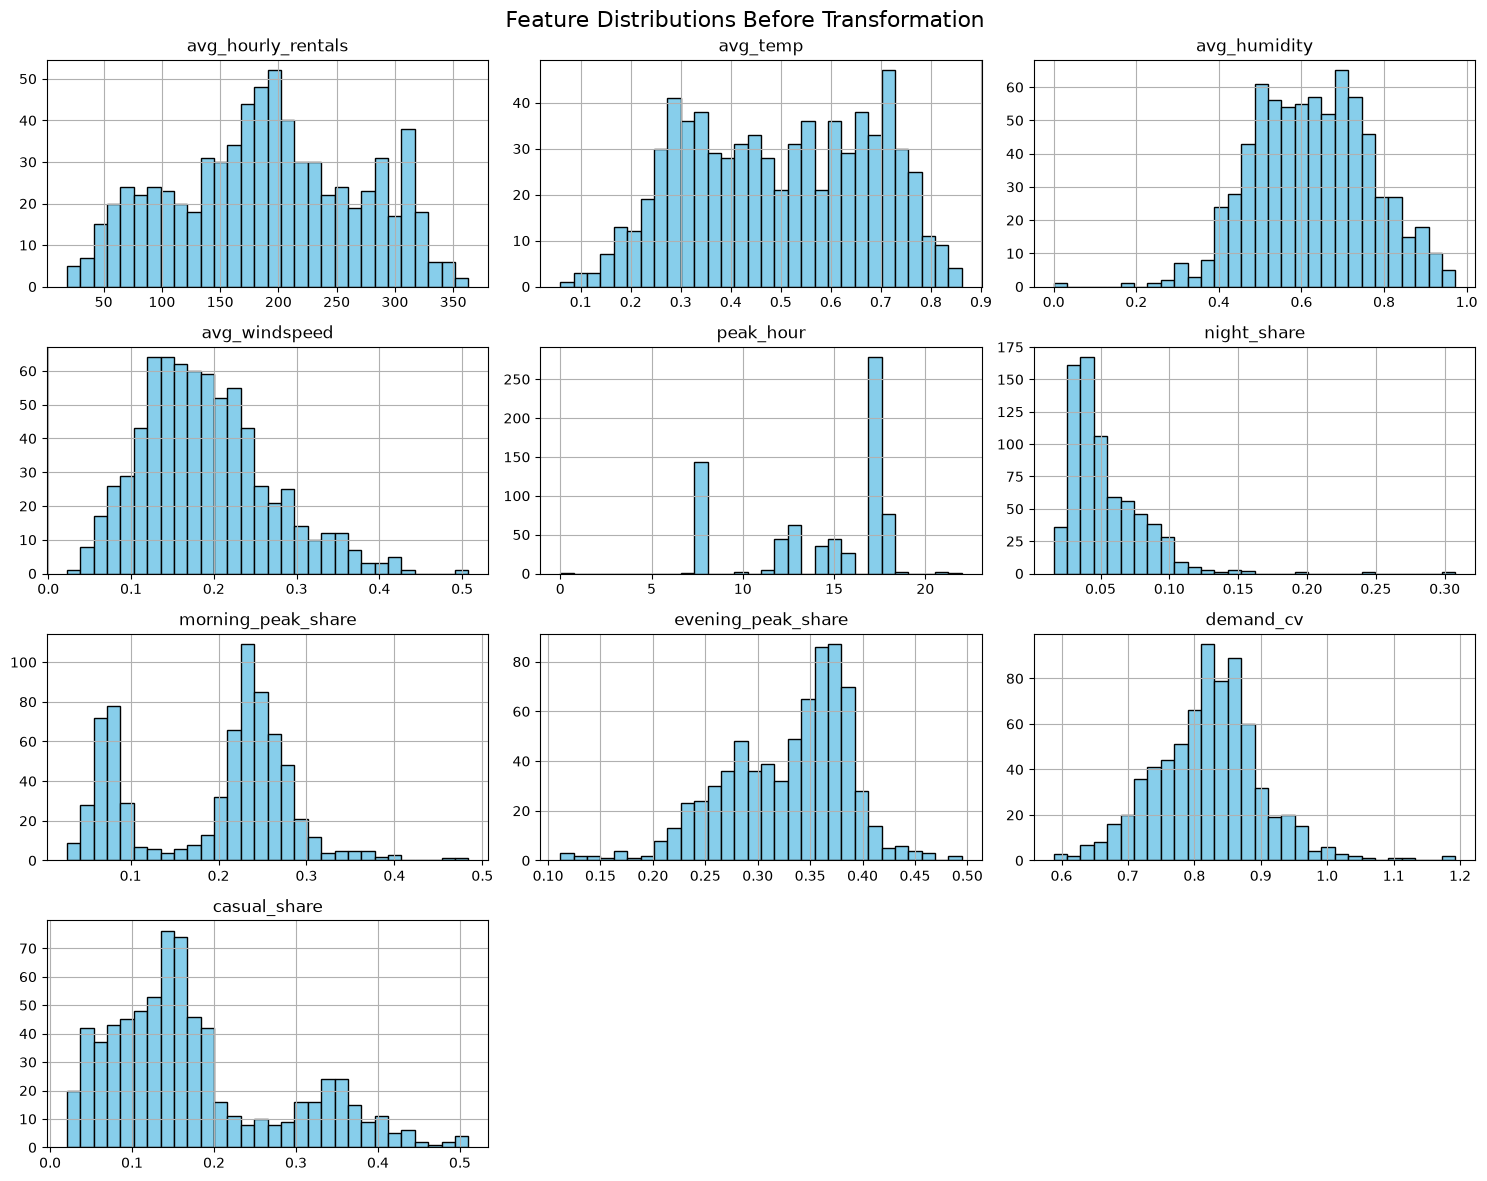

Feature Skewness:
 night_share           2.561089
casual_share          0.941105
avg_windspeed         0.682048
demand_cv             0.281465
avg_hourly_rentals   -0.024681
avg_temp             -0.057926
avg_humidity         -0.068855
morning_peak_share   -0.261408
evening_peak_share   -0.653484
peak_hour            -0.818019
dtype: float64
----------------------------------------


In [23]:
# 1. Visually examine the distributions using histograms
final_clustering_df.hist(figsize=(15, 12), bins=30, edgecolor="black", color='skyblue')
plt.suptitle("Feature Distributions Before Transformation", fontsize=16)
plt.tight_layout()
plt.savefig('../images/skewness.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Calculate mathematical skewness
# A general rule of thumb: skewness > 1 (right skewed) or < -1 (left skewed) is considered highly skewed.
skewness = final_clustering_df.skew().sort_values(ascending=False)
print("Feature Skewness:\n", skewness)
print("-" * 40)

The skewness of each feature was mathematically evaluated to ensure suitability for distance-based clustering. Most features exhibited acceptable symmetry (skewness between -1.0 and 1.0). 

However, `night_share` displayed a high right-skewness of **2.56**, indicating that while night rentals are usually low, a few days experience abnormal late-night spikes. Initially, a logarithmic transformation (`np.log1p`) was attempted to normalize this distribution. Because `night_share` represents a very small proportion (decimal values close to 0), the `log1p` transformation was mathematically ineffective at pulling in the distribution's tail. 

Consequently, a square root transformation (`np.sqrt`) was applied instead. This is the statistical standard for correcting right-skewness in percentage-based data, and it successfully normalized the feature to prevent extreme values from distorting the cluster centroids.

In [24]:
high_skew_features = skewness[skewness > 1.0].index.tolist()

for feature in high_skew_features:
    # Use square root instead of log1p for percentage shares
    final_clustering_df[feature] = np.sqrt(final_clustering_df[feature])
    print(f"Applied square root transformation to fix right-skewness in:{feature}")

Applied square root transformation to fix right-skewness in:night_share


In [25]:
# 2. Calculate mathematical skewness
# A general rule of thumb: skewness > 1 (right skewed) or < -1 (left skewed) is considered highly skewed.
skewness = final_clustering_df.skew().sort_values(ascending=False)
print("Feature Skewness:\n", skewness)
print("-" * 40)

Feature Skewness:
 night_share           1.208745
casual_share          0.941105
avg_windspeed         0.682048
demand_cv             0.281465
avg_hourly_rentals   -0.024681
avg_temp             -0.057926
avg_humidity         -0.068855
morning_peak_share   -0.261408
evening_peak_share   -0.653484
peak_hour            -0.818019
dtype: float64
----------------------------------------


### 1.3.2 Feature Standardization

Distance-based clustering algorithms (like K-Means and AGNES) are highly sensitive to data scale. Without standardizing, features with large numeric ranges (e.g., `avg_hourly_rentals`) would mathematically dominate the distance calculations, overpowering the smaller proportional features (e.g., `casual_share`). 

We apply `StandardScaler` to transform all features to have a mean of 0 and a standard deviation of 1, ensuring every metric contributes equally to the final clusters.

In [26]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(final_clustering_df)
clustering_df_scaled = pd.DataFrame(scaled_data, columns=final_clustering_df.columns, index=final_clustering_df.index)

print("Standardized Feature Preview:")
clustering_df_scaled.head()

Standardized Feature Preview:


,avg_hourly_rentals,avg_temp,avg_humidity,avg_windspeed,peak_hour,night_share,morning_peak_share,evening_peak_share,demand_cv,casual_share
dteday,,,,,,,,,,
2011-01-01,-1.874431,-0.837574,1.265534,-0.381425,0.193529,2.962261,-1.864605,-1.559761,0.181210,1.490245
2011-01-02,-1.952862,-0.731586,0.491518,0.762258,-0.623132,0.935547,-1.737224,-0.820681,0.428438,-0.119424
2011-01-03,-1.618574,-1.648765,-1.333838,0.759271,0.737969,-1.800899,0.636242,0.703709,-0.318377,-0.815482
2011-01-04,-1.535357,-1.628807,-0.253622,-0.383374,0.737969,-1.878586,0.780321,0.811524,0.762303,-1.000367
2011-01-05,-1.514510,-1.480861,-1.336068,-0.037980,-1.712012,-1.350880,0.865290,0.567261,0.235823,-1.167331


## Part 1.4 — Exploratory Visualisation

### 1.4.1 Boxplots of Daily Mobility Features

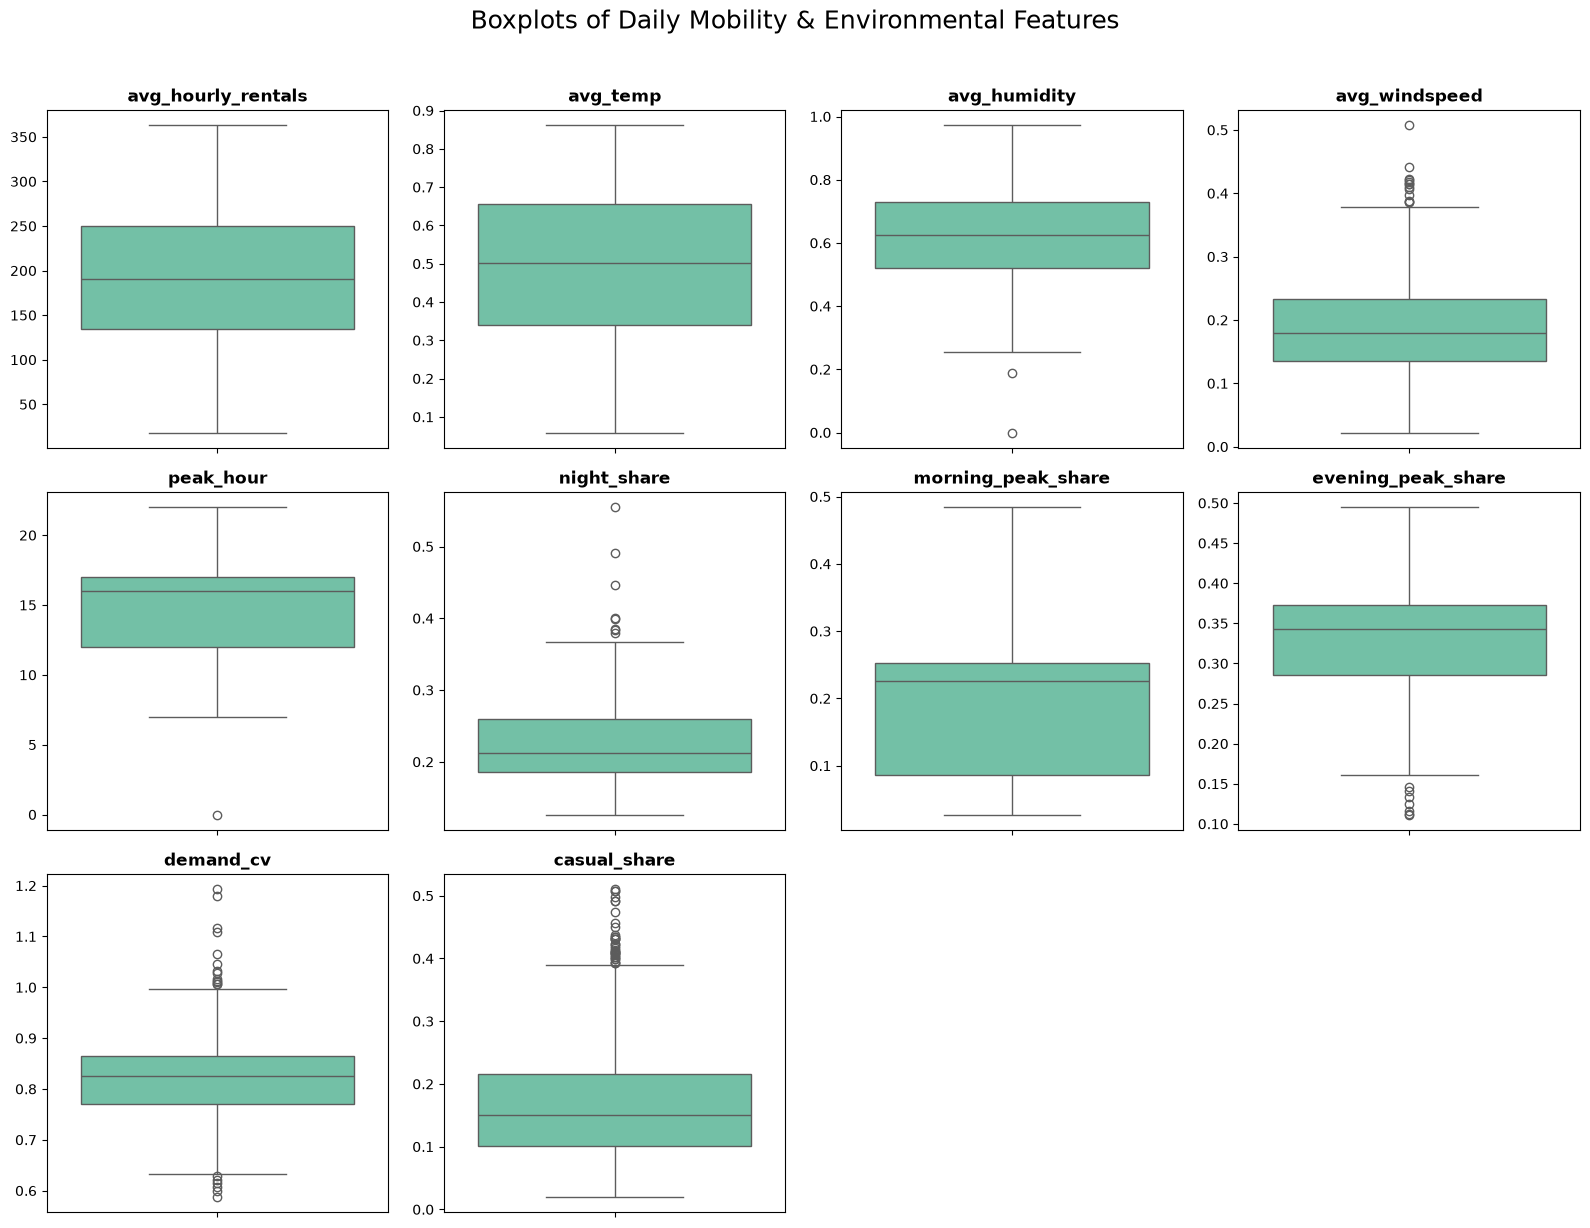

In [27]:
plt.figure(figsize=(16, 12))

# Loop through each column in your unscaled final dataset
for i, col in enumerate(final_clustering_df.columns, 1):
    plt.subplot(3, 4, i)
    # Use seaborn to create a nice looking boxplot
    sns.boxplot(y=final_clustering_df[col], color='mediumaquamarine')
    plt.title(col, fontsize=12, fontweight='bold')
    plt.ylabel('') # Hide y-label for cleaner look

# Add a main title and adjust layout so they don't overlap
plt.suptitle("Boxplots of Daily Mobility & Environmental Features", fontsize=18, y=1.02)
plt.tight_layout()

# Optional: Save the plot for your report
plt.savefig('../images/mobility_boxplots.png', dpi=300, bbox_inches='tight')

plt.show()

Boxplots of the unscaled dataset reveal key distribution patterns and natural outliers:

*   **Rider Behavior:** Upper outliers in `casual_share` and `night_share` reflect genuine high-activity periods (e.g., weekends or late-night events) and are retained, as identifying these unique days is the goal of clustering.
*   **Environmental Extremes:** While `avg_temp` is uniformly distributed, outliers in `avg_windspeed` (high) and `avg_humidity` (low) successfully capture days with extreme weather.
*   **Peak Time Tendencies:** The median `peak_hour` rests between 16:00 and 17:00. Overall, `evening_peak_share` maintains a higher median than `morning_peak_share`, pointing to heavier evening commutes.
*   **Demand Volatility:** The `demand_cv` metric (median ~0.82) is stable overall but contains high/low outliers that perfectly capture unusually erratic or flat demand days.


### 1.4.2 Correlation heatmap of the candidate clustering features
Used to spot any remaining highly correlated/redundant features before standardisation and to sanity-check the feature-removal decisions made in Part 1.3.

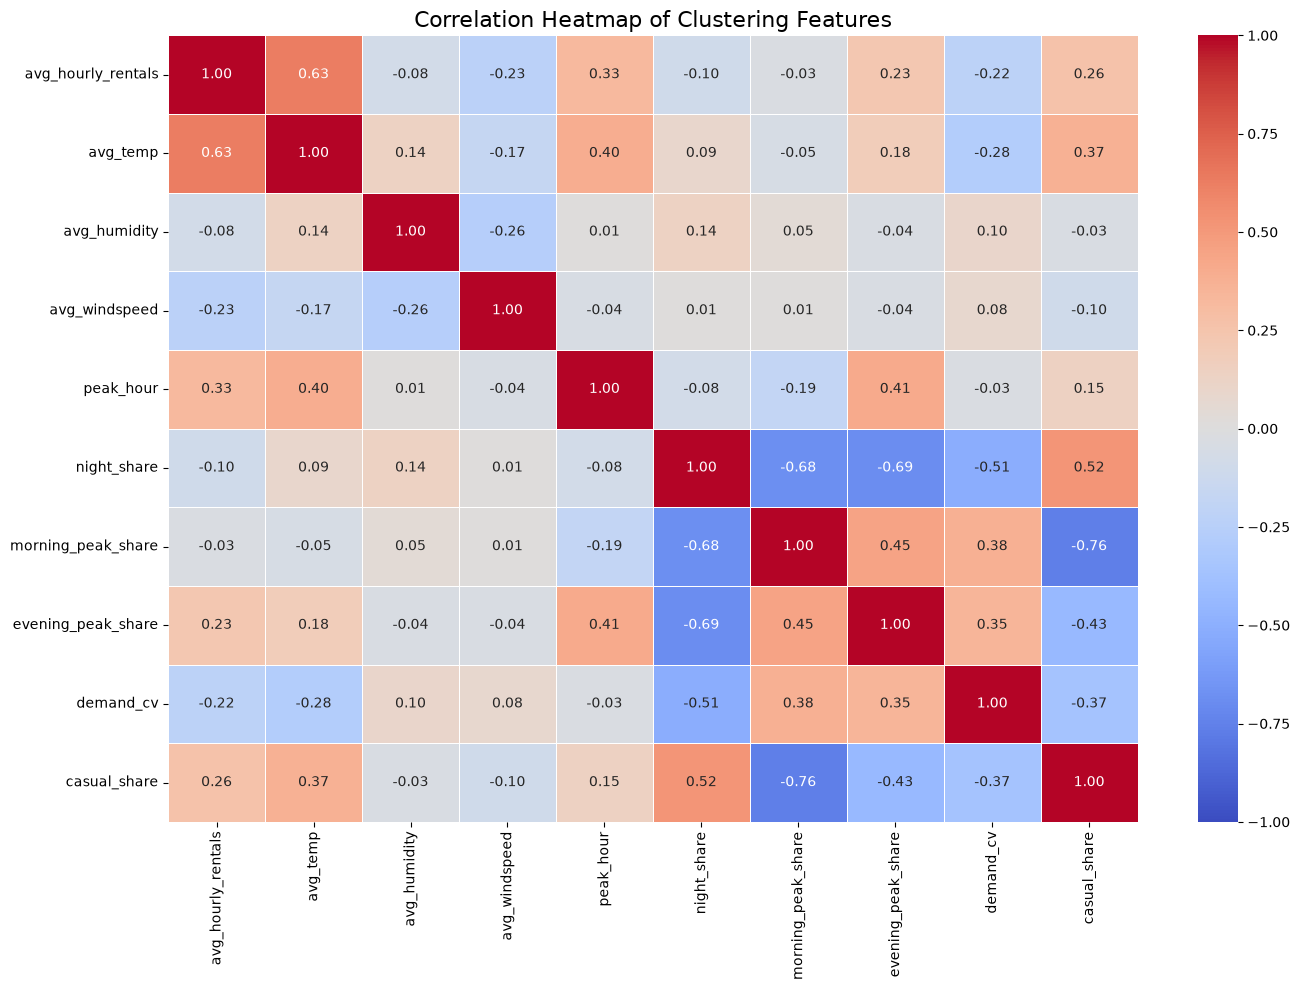

In [28]:
# 1. Calculate the Pearson correlation matrix
corr_matrix = clustering_df_scaled.corr()

# 2. Set up the matplotlib figure (making it large enough to read easily)
plt.figure(figsize=(14, 10))

# 3. Draw the heatmap
# annot=True puts the numbers in the squares
# cmap='coolwarm' uses blue for negative correlation and red for positive
# fmt=".2f" rounds the numbers to two decimal places
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)

plt.title("Correlation Heatmap of Clustering Features", fontsize=16)
plt.tight_layout()
plt.savefig('../images/first_correlation_heatmap_V3.png', dpi=300, bbox_inches='tight')
plt.show()

### 1.4.2 Daily Rental Pattern Analysis

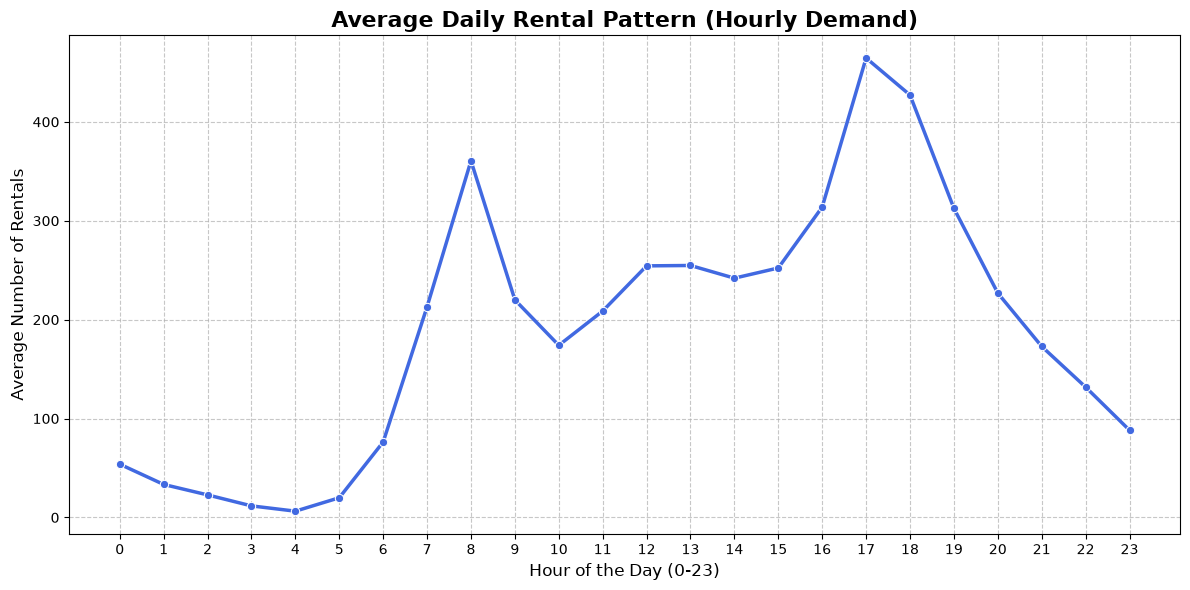

In [29]:
hourly_pattern = df_clean.groupby('hr')['cnt'].mean().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_pattern, 
    x='hr', 
    y='cnt', 
    marker='o', 
    linewidth=2.5, 
    color='royalblue'
)

plt.title("Average Daily Rental Pattern (Hourly Demand)", fontsize=16, fontweight='bold')
plt.xlabel("Hour of the Day (0-23)", fontsize=12)
plt.ylabel("Average Number of Rentals", fontsize=12)

# Ensure every hour is labeled on the x-axis
plt.xticks(range(0, 24)) 
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Optional: Save for your report
plt.savefig('../images/Daily_Rental_Pattern.png', dpi=300, bbox_inches='tight')
plt.show()

To understand the typical shape of bike-sharing demand, the average rentals across all 24 hours of the day were plotted. The resulting curve exhibits a distinct bimodal (two-peaked) distribution:

*   **Commuter Peaks:** A sharp morning spike occurs around 08:00, followed by a larger, broader evening peak starting around 17:00. This strongly indicates that the primary use of the bike-sharing system is urban commuting to and from work.
*   **Off-Peak Baselines:** Demand is lowest during the late-night hours (00:00 - 05:00) and maintains a moderate, steady baseline during midday hours. 

### 1.4.3 Two-Dimensional Visualisation using PCA

To visualize the high-dimensional clustering dataset in a 2D space, Principal Component Analysis (PCA) was applied to the standardized features.

Variance captured by PC1: 31.44%
Variance captured by PC2: 22.67%
Total variance captured: 54.11%


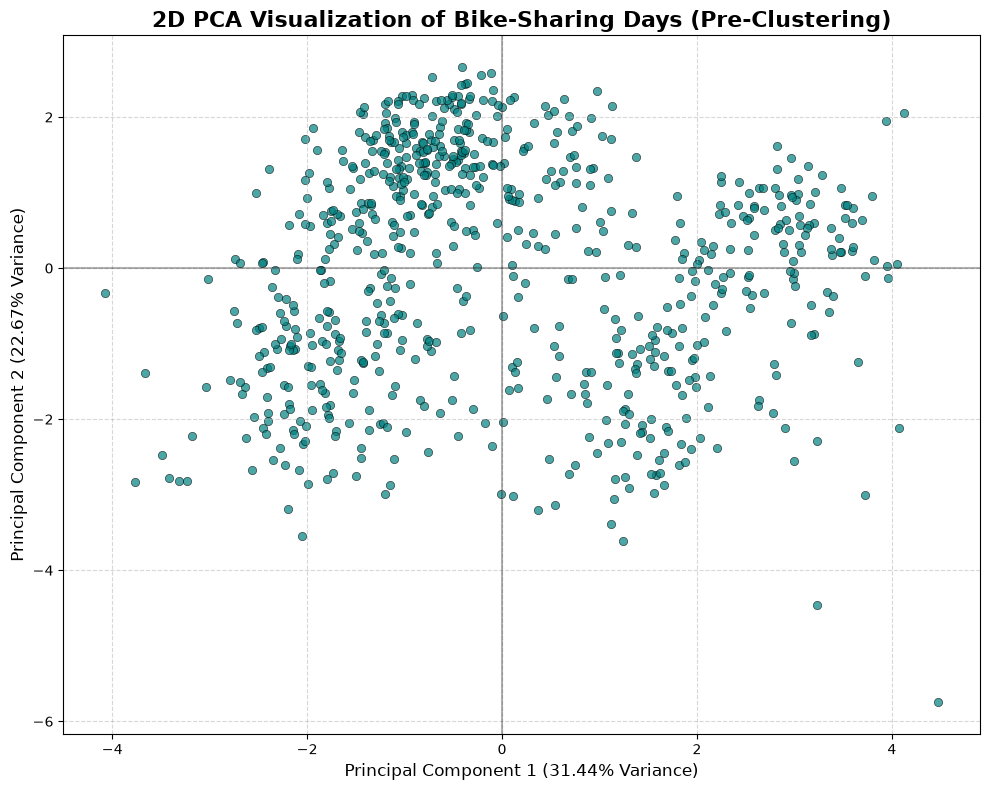

In [30]:
pca = PCA(n_components=2)

# 2. Fit and transform the SCALED dataset
pca_features = pca.fit_transform(clustering_df_scaled)

# 3. Create a temporary dataframe for easy plotting
pca_df = pd.DataFrame(data=pca_features, columns=['PC1', 'PC2'])

# 4. Calculate how much variance (information) these two components capture
explained_variance = pca.explained_variance_ratio_
print(f"Variance captured by PC1: {explained_variance[0]:.2%}")
print(f"Variance captured by PC2: {explained_variance[1]:.2%}")
print(f"Total variance captured: {sum(explained_variance):.2%}")

# 5. Plot the 2D PCA representation
plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', data=pca_df, alpha=0.7, color='teal', edgecolor='k')

plt.title("2D PCA Visualization of Bike-Sharing Days (Pre-Clustering)", fontsize=16, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({explained_variance[0]:.2%} Variance)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({explained_variance[1]:.2%} Variance)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(y=0, color='k', linestyle='-', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='-', alpha=0.3)
plt.tight_layout()

# Optional: Save for your report
plt.savefig('../images/pca_2d_plot.png', dpi=300, bbox_inches='tight')
plt.show()

**Pre-Clustering Observations:**
*   The scatter plot reveals a continuous, dense cloud of data points without clearly separated, distinct islands.

## Part 2: Apply and Analyse Clustering Methods

### 2.1 K-Means Clustering

#### Investigating the Optimal Number of Clusters (k)
To apply the K-Means algorithm effectively, we must first determine the optimal number of clusters ($k$) to partition our daily mobility data. Since K-Means requires $k$ to be defined a priori, we evaluate a range of potential cluster sizes (from $k=2$ to $k=10$) using two standard diagnostic metrics:

1.  **The Elbow Method (Inertia):** This calculates the Within-Cluster Sum of Squares (WCSS). We look for the "elbow" point in the graph where the rate of variance drop slows down significantly, indicating that adding more clusters yields diminishing returns.
2.  **The Silhouette Score:** This measures cluster cohesion (how close points are to their own cluster) versus separation (how far points are from other clusters). The score ranges from -1 to 1, and we seek the value of $k$ that produces the highest peak, representing well-defined clusters.

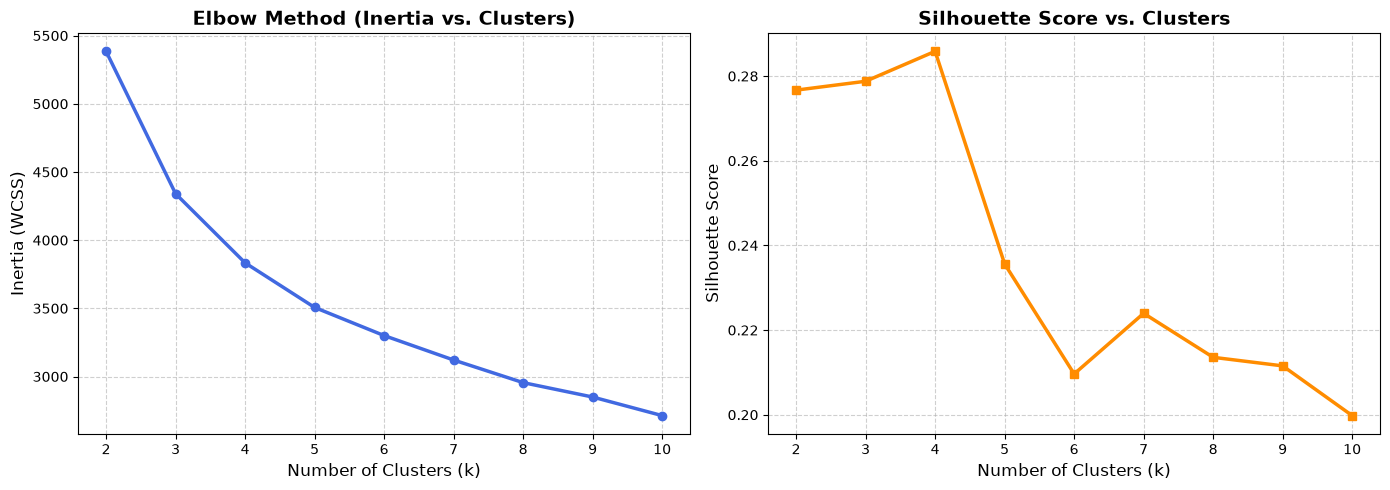

In [31]:
# 1. Define the range of clusters to test
k_range = range(2, 11)
inertia_values = []
silhouette_scores = []

# 2. Iterate through each k to calculate metrics
for k in k_range:
    # Initialize K-Means (n_init=10 is best practice to avoid local minima traps)
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    
    # Fit the model on the standardized dataset
    kmeans.fit(clustering_df_scaled)
    
    # Store the Inertia (WCSS)
    inertia_values.append(kmeans.inertia_)
    
    # Calculate and store the Silhouette Score
    score = silhouette_score(clustering_df_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# 3. Create a side-by-side visualization
plt.figure(figsize=(14, 5))

# Subplot 1: Elbow Method
plt.subplot(1, 2, 1)
plt.plot(k_range, inertia_values, marker='o', color='royalblue', linewidth=2.5)
plt.title('Elbow Method (Inertia vs. Clusters)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (WCSS)', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker='s', color='darkorange', linewidth=2.5)
plt.title('Silhouette Score vs. Clusters', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../images/kmeans_elbow_Sihouttle.png', dpi=300, bbox_inches='tight')
plt.show()

### Final Cluster Selection

Based on the evaluation metrics visualized in the plots, the final number of clusters selected for the K-Means algorithm is **k = 4**. 

**Reasoning:**
*   **Silhouette Score:** The silhouette score reaches its absolute peak at $k=4$ (scoring approximately **0.285**). This mathematical maximum indicates that 4 clusters provide the highest degree of cluster cohesion (points are close to their own cluster center) and separation (points are far from other cluster centers). 
*   **Elbow Method:** The inertia (WCSS) plot shows a steady decline, with a noticeable inflection point or "elbow" occurring at $k=4$. Beyond this point, the rate of variance reduction slows down, indicating that adding a 5th or 6th cluster yields diminishing returns and risks overfitting the data.

Because both independent metrics perfectly align at $k=4$, it represents the most robust and statistically sound configuration for grouping the daily mobility profiles.

### Extracting Cluster Centroids

To understand what each of our 4 clusters represents, we need to examine their centroids (the mathematical center of each cluster). 

Because the data was standardized and transformed prior to clustering, the raw centroid coordinates are difficult to interpret. The following code extracts the centroids for $k=4$ and applies inverse transformations (reversing the `StandardScaler` and the square root transformation on `night_share`) to return the values to their original, real-world scales.

In [32]:
# 1. Initialize and fit the final K-Means model with exactly 4 clusters
kmeans_final = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
kmeans_final.fit(clustering_df_scaled)

# 2. Extract the scaled cluster centroids
scaled_centroids = kmeans_final.cluster_centers_

# 3. Inverse transform the centroids back to the original scale
original_centroids_array = scaler.inverse_transform(scaled_centroids)

# 4. Create a clean DataFrame for the centroids
centroids_df = pd.DataFrame(
    original_centroids_array, 
    columns=final_clustering_df.columns
)

# 5. Reverse the square root transformation applied to 'night_share'
if 'night_share' in centroids_df.columns:
    centroids_df['night_share'] = centroids_df['night_share'] ** 2

# 6. Format the table for easy reading
centroids_df.index = [f"Cluster {i}" for i in range(4)]
print("Cluster Centroids (Original Scale):")

# Transpose (.T) so features are rows and clusters are columns
display(centroids_df.T)

Cluster Centroids (Original Scale):


,Cluster 0,Cluster 1,Cluster 2,Cluster 3
avg_hourly_rentals,240.565289,221.910545,108.699145,133.514302
avg_temp,0.631903,0.582152,0.306819,0.330591
avg_humidity,0.641260,0.630426,0.598758,0.625225
avg_windspeed,0.168448,0.185891,0.212164,0.200278
peak_hour,13.417323,17.160714,14.090090,8.704698
night_share,0.079046,0.039829,0.079154,0.036615
morning_peak_share,0.084624,0.228454,0.077958,0.289574
evening_peak_share,0.276545,0.372759,0.258615,0.325713
demand_cv,0.744027,0.834358,0.820972,0.857003
casual_share,0.345294,0.143231,0.222617,0.072536


| Feature | Cluster 0 | Cluster 1 | Cluster 2 | Cluster 3 |
| :--- | :--- | :--- | :--- | :--- |
| **avg_hourly_rentals** | 240.57 | 221.91 | 108.70 | 133.51 |
| **avg_temp** | 0.632 | 0.582 | 0.307 | 0.331 |
| **avg_humidity** | 0.641 | 0.630 | 0.599 | 0.625 |
| **avg_windspeed** | 0.168 | 0.186 | 0.212 | 0.200 |
| **peak_hour** | 13.42 | 17.16 | 14.09 | 8.70 |
| **night_share** | 0.079 | 0.040 | 0.079 | 0.037 |
| **morning_peak_share** | 0.085 | 0.228 | 0.078 | 0.290 |
| **evening_peak_share**| 0.277 | 0.373 | 0.259 | 0.326 |
| **demand_cv** | 0.744 | 0.834 | 0.821 | 0.857 |
| **casual_share** | 0.345 | 0.143 | 0.223 | 0.073 |

**Cluster Summaries:**
*   **Cluster 0 (Warm Leisure & Weekend Days):** This cluster has the highest overall rental volume and highest average temperature. Commuting shares are very low, the peak hour occurs in the early afternoon (~13:00), and it boasts the highest casual rider share (34.5%). This heavily indicates warm weekends or holidays.
*   **Cluster 1 (Warm Commuting Weekdays):** Characterized by high daily volume and prominent commuter behavior. The peak hour sits perfectly at evening rush hour (~17:00), and both morning and evening peak shares are strong. Casual share is relatively low, pointing to registered users commuting in good weather.
*   **Cluster 2 (Low-Demand & Adverse Weather Days):** This cluster exhibits the lowest average temperatures, the highest windspeeds, and significantly depressed rental counts (less than half of Cluster 0). The peak hour falls mid-afternoon with low morning commute shares, likely indicating cold or stormy weekends where overall system usage plummets.
*   **Cluster 3 (Cold Commuting Weekdays):** Despite low temperatures similar to Cluster 2, this cluster shows fierce commuter loyalty. It has the highest morning peak share (29%), a peak hour situated sharply in the morning (~08:00), and the absolute lowest casual rider share (7.3%). These are standard weekdays in winter where only dedicated, registered commuters use the bikes.

### Visualising Clusters using PCA

To visualize how well our K-Means algorithm separated the days into 4 distinct groups, we use Principal Component Analysis (PCA) to compress our multi-dimensional feature space down to 2 summary dimensions. This allows us to plot the high-dimensional clusters on a standard 2D scatter plot.

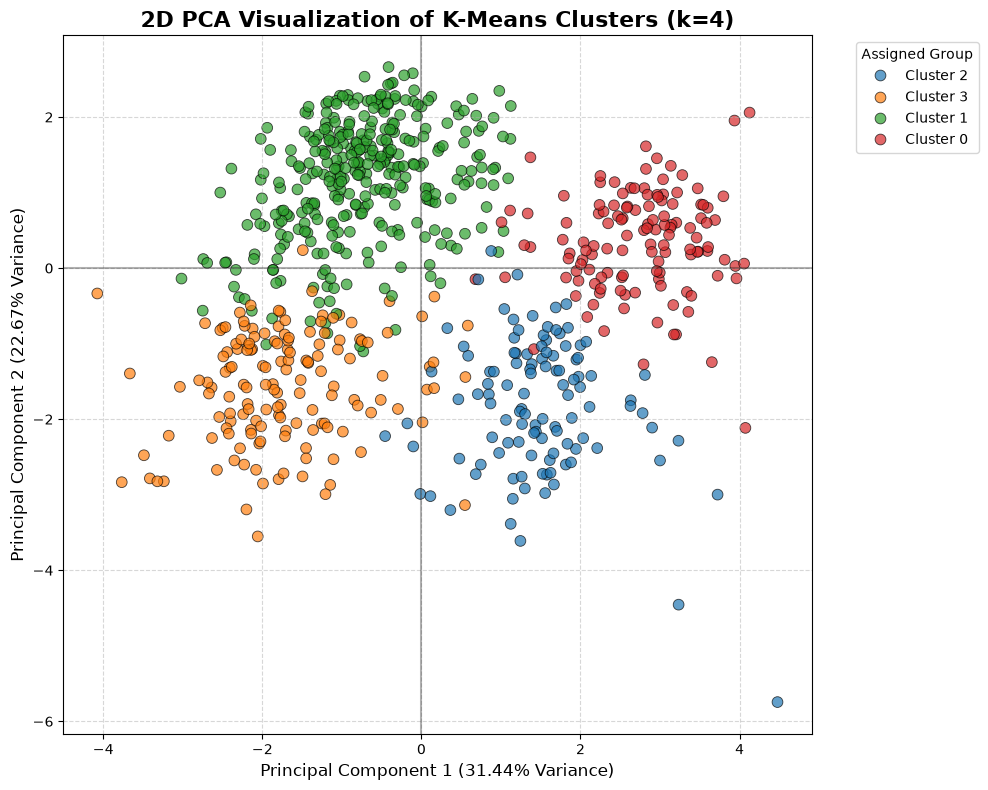

In [33]:
# 1. Initialize PCA to extract 2 principal components
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(clustering_df_scaled)

# 2. Create a DataFrame containing the two components
pca_df = pd.DataFrame(data=pca_features, columns=['PC1', 'PC2'])

# 3. Append the cluster labels from our final K-Means model
# We convert them to strings so Seaborn treats them as discrete categories, not a continuous color gradient
pca_df['Cluster'] = kmeans_final.labels_
pca_df['Cluster'] = 'Cluster ' + pca_df['Cluster'].astype(str)

# 4. Extract explained variance for the axis labels
explained_variance = pca.explained_variance_ratio_

# 5. Create the scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Cluster', 
    palette='tab10', 
    data=pca_df, 
    alpha=0.7, 
    edgecolor='k',
    s=60
)

# 6. Formatting
plt.title("2D PCA Visualization of K-Means Clusters (k=4)", fontsize=16, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({explained_variance[0]:.2%} Variance)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({explained_variance[1]:.2%} Variance)", fontsize=12)
plt.axhline(y=0, color='k', linestyle='-', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='-', alpha=0.3)
plt.legend(title='Assigned Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save and display
plt.savefig('../images/pca_cluster_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
# 1. Add the K-Means cluster labels to your daily_features dataframe
daily_features['Cluster'] = kmeans_final.labels_

# 2. Cross-tabulate Clusters with 'workingday' (usually 0 = Weekend/Holiday, 1 = Workday)
print("Working Day Distribution per Cluster:")
workingday_check = pd.crosstab(daily_features['Cluster'], daily_features['workingday'])
display(workingday_check)

# 3. Cross-tabulate Clusters with 'season' (to prove the Warm vs. Cold weather deductions)
print("\nSeason Distribution per Cluster:")
season_check = pd.crosstab(daily_features['Cluster'], daily_features['season'])
display(season_check)

Working Day Distribution per Cluster:


workingday,0,1
Cluster,,
0,121,6
1,4,332
2,104,7
3,0,149



Season Distribution per Cluster:


season,1,2,3,4
Cluster,,,,
0,2,43,61,21
1,33,115,119,69
2,64,11,0,36
3,78,15,6,50


*Cluster Summaries:**

*   **Cluster 0 (Warm Leisure & Weekends):** Dominated by casual riders (34.5% share) with a single midday peak (~13:00). High temperatures and high total volume indicate pleasant weather. **Validation:** The cross-tabulation confirms this, as 121 out of 127 days in this cluster are non-working days (weekends/holidays), predominantly occurring in seasons 2 and 3 (Spring/Summer).
*   **Cluster 1 (Warm Commuting Weekdays):** Standard warm-weather commuting days. These feature high total volume, strong morning and evening commuter shares, and an evening peak hour (~17:00). **Validation:** 332 out of 336 days in this cluster are official working days, heavily concentrated in the warmer seasons.
*   **Cluster 2 (Low-Demand / Cold Weekends):** Characterized by the absolute lowest rental volumes in the dataset. Low temperatures, high windspeeds, and a lack of commuter spikes indicate depressed usage. **Validation:** 104 out of 111 of these days are non-working days, primarily occurring in seasons 1 and 4 (Winter/Fall). This perfectly captures miserable weekend weather where neither commuters nor casual riders use the system.
*   **Cluster 3 (Cold Commuting Weekdays):** Despite cold temperatures, loyal commuters still use the system. This cluster has the highest morning commuter share (29%), a sharp morning peak (~08:00), and the lowest casual rider share (7%). **Validation:** An incredible 149 out of 149 days in this cluster are working days, entirely dominated by seasons 1 and 4 (Winter/Fall).

### 2.2 Hierarchical Clustering using AGNES

Agglomerative Nesting (AGNES) is a bottom-up hierarchical clustering approach. To determine the most appropriate grouping structure, the algorithm was applied using three distinct linkage criteria:
1.  **Single Linkage:** Merges clusters based on the shortest distance between their closest points.
2.  **Complete Linkage:** Merges clusters based on the longest distance between their furthest points.
3.  **Average Linkage:** Merges clusters based on the average distance between all points in the two clusters.

First, we visually inspect the hierarchical structures using dendrograms. Next, we quantitatively evaluate the optimal cluster cuts for each linkage method using the Silhouette Score to ensure a mathematically robust final selection.

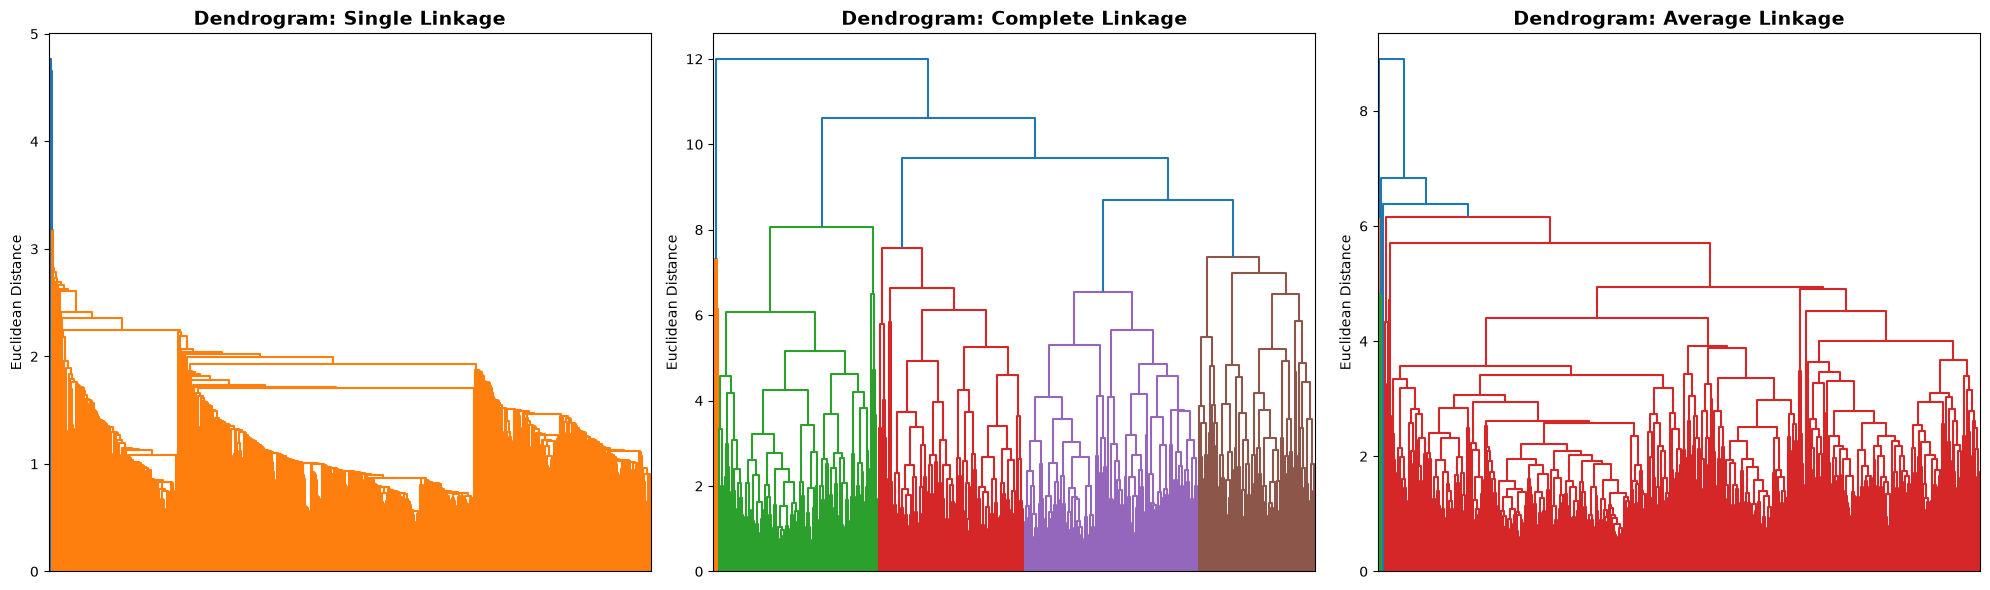

In [35]:
plt.figure(figsize=(20, 6))

# 1. Single Linkage Dendrogram
plt.subplot(1, 3, 1)
plt.title("Dendrogram: Single Linkage", fontsize=14, fontweight='bold')
shc.dendrogram(shc.linkage(clustering_df_scaled, method='single'), no_labels=True)
plt.ylabel("Euclidean Distance")

# 2. Complete Linkage Dendrogram
plt.subplot(1, 3, 2)
plt.title("Dendrogram: Complete Linkage", fontsize=14, fontweight='bold')
shc.dendrogram(shc.linkage(clustering_df_scaled, method='complete'), no_labels=True)
plt.ylabel("Euclidean Distance")

# 3. Average Linkage Dendrogram
plt.subplot(1, 3, 3)
plt.title("Dendrogram: Average Linkage", fontsize=14, fontweight='bold')
shc.dendrogram(shc.linkage(clustering_df_scaled, method='average'), no_labels=True)
plt.ylabel("Euclidean Distance")

plt.tight_layout()
plt.savefig('../images/dendrograms_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

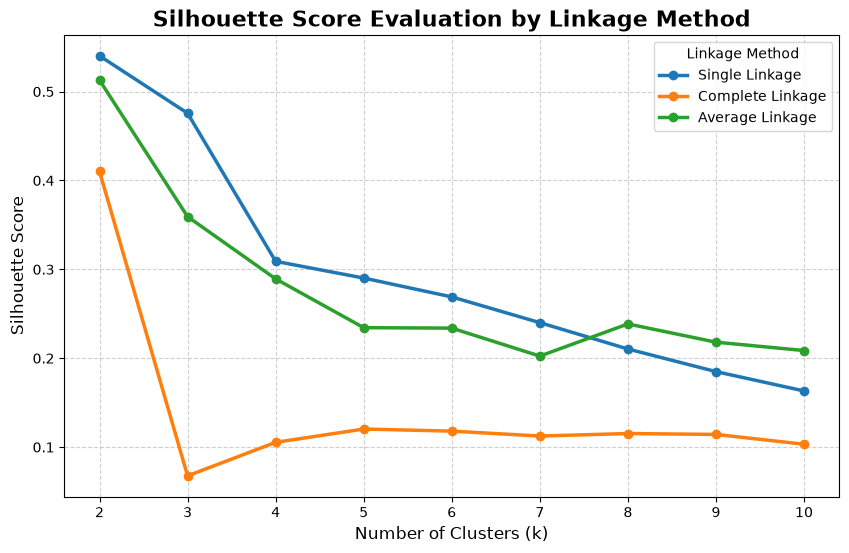

In [36]:
linkage_methods = ['single', 'complete', 'average']
k_range = range(2, 11)

plt.figure(figsize=(10, 6))

# Loop through each linkage method to calculate and plot Silhouette Scores
for method in linkage_methods:
    scores = []
    for k in k_range:
        # Initialize AGNES with the specific linkage and k
        agnes = AgglomerativeClustering(n_clusters=k, linkage=method)
        cluster_labels = agnes.fit_predict(clustering_df_scaled)
        
        # Calculate score
        score = silhouette_score(clustering_df_scaled, cluster_labels)
        scores.append(score)
    
    # Plot the line for this linkage method
    plt.plot(k_range, scores, marker='o', linewidth=2.5, label=f"{method.capitalize()} Linkage")

plt.title("Silhouette Score Evaluation by Linkage Method", fontsize=16, fontweight='bold')
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.xticks(k_range)
plt.legend(title="Linkage Method", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.savefig('../images/agnes_silhouette_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

### Analysis of Linkage Methods and Cluster Cuts

To determine the optimal hierarchical structure, the three linkage methods were evaluated visually via their dendrograms and quantitatively using the Silhouette Score.

**Visual Dendrogram Analysis:**
*   **Single Linkage:** The dendrogram exhibits severe "chaining." Rather than forming distinct, balanced groups, the algorithm sequentially merges individual outlier points into one massive primary cluster.
*   **Average Linkage:** While slightly more structured than Single Linkage, it still suffers from significant chaining and fails to partition the main body of data into evenly distributed subgroups.
*   **Complete Linkage:** Reduces the severe chaining seen with the other linkage methods. Its clearer vertical gaps suggest a candidate cut at 4 clusters; cluster balance is evaluated separately in Part 3.

**Quantitative Evaluation (Silhouette Scores):**
*   **Single & Average Linkage:** Both methods achieved high Silhouette Scores for $k=2$ (roughly 0.54 and 0.51). However, cross-referencing this with their dendrograms reveals this is a mathematical artifact; the score is inflated because the algorithm simply isolated a single outlier point from the rest of the dataset. As $k$ increases, their scores steadily decline.
*   **Complete Linkage:** While its overall numerical scores are lower than the other methods, it shows a much more realistic evaluation of the central data mass, dropping initially before stabilizing. The lower score is a natural result of the algorithm actively partitioning the dense, complex central data cloud rather than artificially inflating its score by picking off easy outliers.

### 2.2.2 Final Linkage Selection

Although Single Linkage at $k=2$ yielded the highest strict numerical Silhouette Score, it completely fails to produce a **meaningful** segmentation of daily mobility profiles due to severe chaining. 

Therefore, **Complete Linkage** is identified as the superior and most meaningful linkage method. Its dendrogram successfully identifies robust, balanced sub-populations within the data. Supported by its well-defined visual structure, a cut yielding **4 distinct clusters** (which aligns perfectly with our earlier K-Means findings) provides the most practical and interpretable grouping for this dataset.

### 2.3 DBSCAN Clustering

To apply DBSCAN effectively, we must determine two key parameters: `min_samples` and `eps`. 

*   **`min_samples`:** Following the standard data science heuristic of $2 \times \text{dimensionality}$, we set this to **20** (since we have 10 features). 
*   **`eps`:** To estimate the optimal neighborhood distance threshold, we generate a $k$-Nearest Neighbors (k-NN) distance plot with $k=20$. By plotting these distances in ascending order, we can identify the "elbow" (the point of maximum curvature) which represents the boundary between dense clusters and sparse noise points.

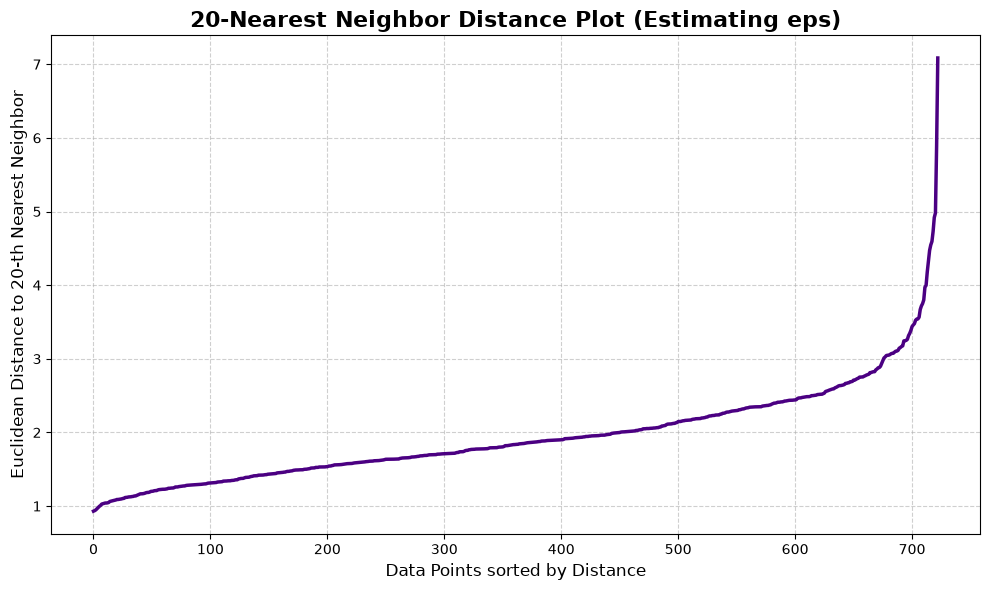

In [37]:
# 1. Define k (aligns with our intended min_samples of 2 * 10 features = 20)
k = 20

# 2. Initialize and fit the NearestNeighbors model on the scaled data
nn = NearestNeighbors(n_neighbors=k)
nn.fit(clustering_df_scaled)

# 3. Retrieve the distances to the k-th nearest neighbor for every point
distances, indices = nn.kneighbors(clustering_df_scaled)

# 4. Extract the distance to the k-th neighbor (the last column) and sort it ascendingly
kth_distances = distances[:, -1]
kth_distances = np.sort(kth_distances)

# 5. Plot the sorted distances to find the "elbow"
plt.figure(figsize=(10, 6))
plt.plot(kth_distances, color='indigo', linewidth=2.5)

plt.title(f"{k}-Nearest Neighbor Distance Plot (Estimating eps)", fontsize=16, fontweight='bold')
plt.xlabel("Data Points sorted by Distance", fontsize=12)
plt.ylabel(f"Euclidean Distance to {k}-th Nearest Neighbor", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save the figure
plt.savefig('../images/dbscan_eps_plot.png', dpi=300, bbox_inches='tight')
plt.show()

#### `eps` Parameter Selection

The k-NN distance plot visualizes the distance to the 20th nearest neighbor for all data points. The optimal `eps` value is located at the "elbow" of the curve, where distances stop growing linearly and begin to spike exponentially into outlier territory. 

Based on visual inspection of the plot, this sharp inflection point occurs at approximately **eps = 3**.

#### Justification of `min_samples` Selection

The `min_samples` parameter dictates the minimum number of data points required to form a dense region (a valid cluster). For this dataset, **min_samples = 20** was selected based on the following justifications:

1.  **Dimensionality Heuristic:** A standard best practice in density-based clustering is to set `min_samples` to at least twice the number of dimensions ($2 \times D$) for datasets with more than two dimensions. Because our dataset utilizes 10 features, $2 \times 10 = 20$ provides a mathematically sound baseline.
2.  **Preventing Micro-Clusters:** Setting the threshold to 20 prevents the algorithm from classifying very small, insignificant anomalies (e.g., 2 or 3 random days with slightly odd weather) as their own standalone clusters. 
3.  **Noise Robustness:** Given the total dataset size (approximately 730 days), requiring 20 days to form a cluster ensures that only genuinely recurring, distinct mobility profiles are identified, while truly unique outlier days are properly relegated to the "noise" category.

### DBSCAN Results: Clusters and Noise

Using the selected parameters of **`eps = 3.0`** and **`min_samples = 20`**, the DBSCAN algorithm was applied to the standardized dataset.

In [38]:
# 1. Initialize DBSCAN with our chosen parameters
dbscan = DBSCAN(eps=3.0, min_samples=20)

# 2. Fit the model and get the cluster labels
dbscan_labels = dbscan.fit_predict(clustering_df_scaled)

# 3. Calculate the number of clusters (ignoring noise)
# DBSCAN assigns a label of -1 to noise points
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

# 4. Calculate the number of noise points
n_noise = list(dbscan_labels).count(-1)

# 5. Print the results
print(f"Estimated number of clusters: {n_clusters}")
print(f"Estimated number of noise points: {n_noise}")

Estimated number of clusters: 1
Estimated number of noise points: 8


The algorithm produced the following results:
*   **Total Clusters Identified:** 1
*   **Total Noise Points (Outliers):** 8

### DBSCAN Sensitivity Analysis

DBSCAN is famously sensitive to its hyperparameter configuration. To understand how dependent our single-cluster result is on the exact parameters chosen, we will investigate the model's sensitivity by testing two alternative configurations:
1.  **Stricter Distance (eps = 2.5, min_samples = 20):** Decreasing the neighborhood radius forces the algorithm to require higher density to form clusters. This typically results in more noise and may fragment a large single cluster into multiple smaller ones.
2.  **Lower Density Requirement (eps = 3.0, min_samples = 10):** Halving the minimum sample requirement allows smaller groups of similar days (micro-clusters) to form their own valid clusters rather than being absorbed or classified as noise.

In [39]:
# Alternative 1: Stricter distance (lower eps)
dbscan_alt1 = DBSCAN(eps=2.5, min_samples=20)
labels_alt1 = dbscan_alt1.fit_predict(clustering_df_scaled)
n_clusters_alt1 = len(set(labels_alt1)) - (1 if -1 in labels_alt1 else 0)
n_noise_alt1 = list(labels_alt1).count(-1)

# Alternative 2: Lower density requirement (lower min_samples)
dbscan_alt2 = DBSCAN(eps=3.0, min_samples=10)
labels_alt2 = dbscan_alt2.fit_predict(clustering_df_scaled)
n_clusters_alt2 = len(set(labels_alt2)) - (1 if -1 in labels_alt2 else 0)
n_noise_alt2 = list(labels_alt2).count(-1)

# Print comparison
print("--- DBSCAN Sensitivity Analysis ---")
print(f"Base (eps=3.0, min=20): Clusters = 1, Noise = 8")
print(f"Alt 1 (eps=2.5, min=20): Clusters = {n_clusters_alt1}, Noise = {n_noise_alt1}")
print(f"Alt 2 (eps=3.0, min=10): Clusters = {n_clusters_alt2}, Noise = {n_noise_alt2}")

--- DBSCAN Sensitivity Analysis ---
Base (eps=3.0, min=20): Clusters = 1, Noise = 8
Alt 1 (eps=2.5, min=20): Clusters = 1, Noise = 20
Alt 2 (eps=3.0, min=10): Clusters = 1, Noise = 7


#### Sensitivity Analysis Results & Interpretation

Testing alternative parameter settings revealed how the clustering structure responds to varying density definitions:

*   **Alternative 1 (`eps=2.5`, `min_samples=20`):** Produced **1 cluster** and **20 noise points**. Shrinking the neighborhood radius made the density requirement stricter. This more than doubled the amount of noise, indicating that while the core central cluster remains completely intact, the outer edges of the data cloud are sparse and loosely connected.
*   **Alternative 2 (`eps=3.0`, `min_samples=10`):** Produced **1 cluster** and **7 noise points**. Halving the minimum sample requirement barely changed the result from our base model (8 noise points). This proves that the isolated noise points are truly distinct anomalies, not just small, unrecognized micro-clusters waiting to be grouped.

**Conclusion:** The sensitivity analysis confirms that this dataset is highly cohesive. The data overwhelmingly forms one massive, continuous body of "typical" days. Altering the parameters does not fragment this core group into new subgroups; it only slightly shifts the boundary of how strictly we define an outlier.

### Visualising DBSCAN Clusters and Noise

Because our dataset contains 10 dimensions, we cannot visualize the clusters directly. Just as we did with K-Means, we will use Principal Component Analysis (PCA) to reduce the data into a 2D scatter plot.

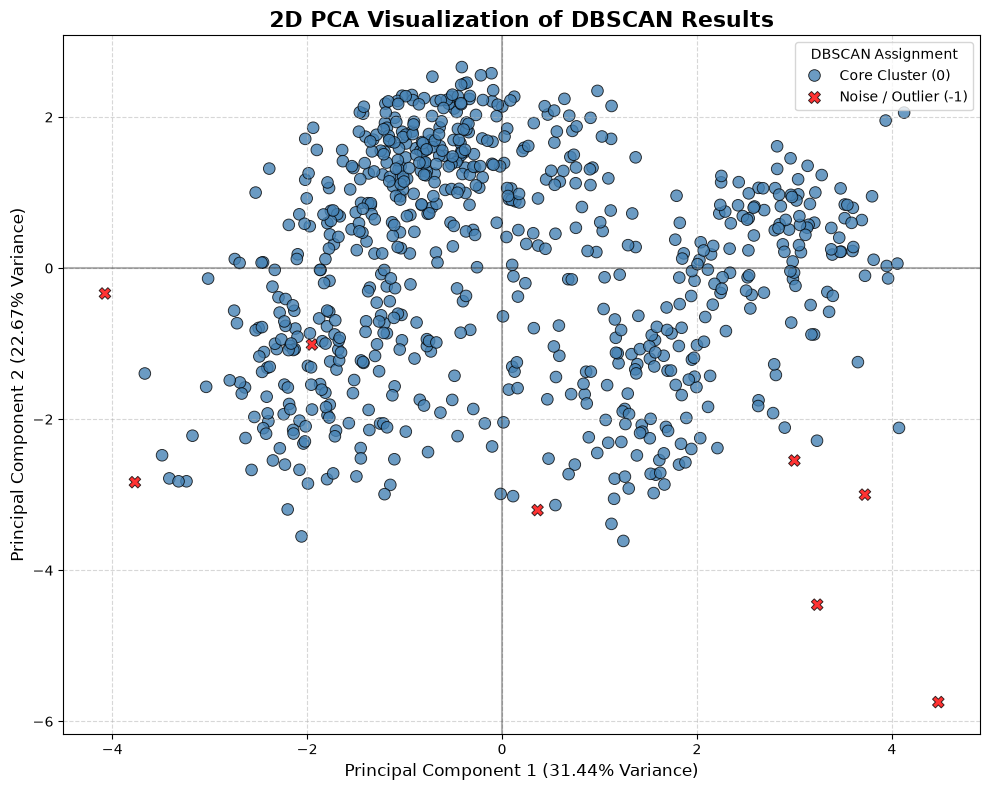

In [40]:
# 1. Re-run PCA to get 2D coordinates (or use existing if available)
pca_dbscan = PCA(n_components=2, random_state=42)
pca_dbscan_features = pca_dbscan.fit_transform(clustering_df_scaled)

# 2. Create a DataFrame for plotting
pca_dbscan_df = pd.DataFrame(data=pca_dbscan_features, columns=['PC1', 'PC2'])
pca_dbscan_df['DBSCAN_Label'] = dbscan_labels

# 3. Map the labels to readable string categories for the legend
pca_dbscan_df['Point Type'] = pca_dbscan_df['DBSCAN_Label'].map({
    -1: 'Noise / Outlier (-1)', 
     0: 'Core Cluster (0)'
})

# 4. Create the scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Point Type', 
    # Use distinct colors: Blue for normal days, bright Red for noise
    palette={'Core Cluster (0)': 'steelblue', 'Noise / Outlier (-1)': 'red'},
    style='Point Type',
    # Use distinct shapes: Circles for normal, 'X' for noise
    markers={'Core Cluster (0)': 'o', 'Noise / Outlier (-1)': 'X'},
    data=pca_dbscan_df, 
    alpha=0.8, 
    edgecolor='k',
    s=70
)

# 5. Formatting
explained_variance = pca_dbscan.explained_variance_ratio_
plt.title("2D PCA Visualization of DBSCAN Results", fontsize=16, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({explained_variance[0]:.2%} Variance)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({explained_variance[1]:.2%} Variance)", fontsize=12)
plt.axhline(y=0, color='k', linestyle='-', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='-', alpha=0.3)
plt.legend(title='DBSCAN Assignment')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save and display
plt.savefig('../images/dbscan_pca_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

# Part 3: Clustering Evaluation and Comparison

To determine the most appropriate clustering algorithm for the mobility dataset, the final meaningful results from K-Means ($k=4$), AGNES (Complete Linkage, $k=4$), and DBSCAN (`eps=3.0`, `min_samples=20`) were quantitatively evaluated.

### 3.1 Quantitative Evaluation Metrics

Each algorithm was evaluated using the following metrics:
1.  **Silhouette Score:** Measures how similar an object is to its own cluster compared to other clusters. Values range from -1 to +1 (higher is better, indicating dense and well-separated clusters).
2.  **Davies-Bouldin (DB) Index:** Calculates the average similarity ratio of each cluster with its most similar cluster. Lower values indicate better clustering (high intra-cluster density and high inter-cluster separation).
3.  **Intra-Cluster Distance:** The average Euclidean distance between data points and their respective cluster centroid (lower is better, indicating compactness).
4.  **Inter-Cluster Distance:** The average Euclidean distance between the centroids of different clusters (higher is better, indicating distinct separation).
5.  **Cluster Size Distribution:** Evaluates whether the algorithm produced balanced sub-populations or highly skewed groupings.

In [41]:
# Average distance to the assigned centroid and average distance between centroids
def calculate_distances(X, labels):
    unique_labels = np.unique(labels)
    centroids = []
    point_to_centroid_dists = []
    
    # Calculate Intra-cluster distances (average distance to centroid)
    for label in unique_labels:
        cluster_points = X[labels == label]
        centroid = cluster_points.mean(axis=0)
        centroids.append(centroid)
        
        point_to_centroid_dists.extend(
            euclidean_distances(cluster_points, [centroid]).ravel()
        )
        
    avg_intra = np.mean(point_to_centroid_dists)
    
    # Calculate Inter-cluster distances (average distance between centroids)
    if len(centroids) > 1:
        inter_dists = euclidean_distances(centroids)
        # Get upper triangle of distance matrix (excluding diagonal 0s)
        avg_inter = inter_dists[np.triu_indices(len(centroids), k=1)].mean()
    else:
        avg_inter = np.nan # Undefined if only 1 cluster
        
    return avg_intra, avg_inter

# Generate each final label set explicitly to avoid reusing a loop variable
agnes_complete_labels = AgglomerativeClustering(
    n_clusters=4, linkage='complete'
).fit_predict(clustering_df_scaled)

# Compile evaluation results
results = []
models = {
    'K-Means (k=4)': kmeans_final.labels_,         # From Part 2.1
    'AGNES (k=4, Complete)': agnes_complete_labels,
    'DBSCAN (eps=3.0, min=20)': dbscan_labels      # From Part 2.3
}

for name, labels in models.items():
    # Preserve noise in the size distribution, but exclude label -1 from metrics
    unique, counts = np.unique(labels, return_counts=True)
    sizes = {int(label): int(count) for label, count in zip(unique, counts)}
    evaluation_mask = labels != -1
    X_evaluation = clustering_df_scaled.values[evaluation_mask]
    labels_evaluation = labels[evaluation_mask]
    n_clusters = len(np.unique(labels_evaluation))

    intra, inter = calculate_distances(X_evaluation, labels_evaluation)
    if n_clusters >= 2:
        sil_score = silhouette_score(X_evaluation, labels_evaluation)
        db_score = davies_bouldin_score(X_evaluation, labels_evaluation)
    else:
        sil_score = np.nan
        db_score = np.nan
    
    results.append({
        'Model': name,
        'Silhouette Score': round(sil_score, 4) if not np.isnan(sil_score) else 'N/A',
        'Davies-Bouldin Index': round(db_score, 4) if not np.isnan(db_score) else 'N/A',
        'Avg Intra-Cluster Dist': round(intra, 4),
        'Avg Inter-Cluster Dist': round(inter, 4) if not np.isnan(inter) else 'N/A',
        'Cluster Sizes': str(sizes)
    })

# 3. Display the Evaluation Table
evaluation_df = pd.DataFrame(results)
display(evaluation_df)

,Model,Silhouette Score,Davies-Bouldin Index,Avg Intra-Cluster Dist,Avg Inter-Cluster Dist,Cluster Sizes
0,K-Means (k=4),0.2858,1.4428,2.1485,3.7272,"{0: 127, 1: 336, 2: 111, 3: 149}"
1,"AGNES (k=4, Complete)",0.1054,1.856,2.6153,4.4476,"{0: 349, 1: 176, 2: 192, 3: 6}"
2,"DBSCAN (eps=3.0, min=20)",N/A,N/A,2.9948,N/A,"{-1: 8, 0: 715}"


### Evaluation Metric Findings

The corrected evaluation generates the AGNES complete-linkage, $k=4$ labels explicitly and excludes DBSCAN noise (label -1) from metric calculations while retaining it in the size distribution.

*   **Internal Validation:** K-Means achieved the best valid scores (Silhouette: 0.2858; DB: 1.4428). Complete-linkage AGNES was weaker (Silhouette: 0.1054; DB: 1.8560). DBSCAN's Silhouette and DB Index are undefined after noise is excluded because only one genuine cluster remains.
*   **Distance Metrics:** K-Means produced an average intra-cluster distance of 2.1485 and inter-cluster distance of 3.7272. AGNES produced 2.6153 and 4.4476 respectively, but its larger centroid separation is influenced by a six-day cluster. DBSCAN's core-cluster intra-distance is 2.9948; inter-cluster distance is undefined.
*   **Cluster Size Distribution:** 
    *   **K-Means:** Successfully divided the data into practical, well-populated sub-groups.
    *   **AGNES:** Produced cluster sizes of 349, 176, 192 and 6 days, including one impractically small cluster.
    *   **DBSCAN:** Grouped 715 days into one core cluster and identified 8 days as noise. Noise was excluded from metric inputs and was not treated as a pseudo-cluster.

### 3.2 Comparison of Clustering Methods

K-Means ($k=4$), Complete-Linkage AGNES ($k=4$), and DBSCAN (`eps=3.0`, `min_samples=20`) are compared based on cluster separation, compactness, parameter sensitivity, cluster-size balance, interpretability, and treatment of unusual observations.

The final method is selected by considering all criteria together rather than choosing the method with the best value for only one metric.

## 3.3 Comparison and Final Selection

K-Means provided the best overall balance of separation and compactness, with a Silhouette Score of **0.2858**, Davies-Bouldin Index of **1.4428**, intra-cluster distance of **2.1485**, and inter-cluster distance of **3.7272**. Its cluster sizes (**127, 336, 111, and 149**) were reasonably balanced and represented four interpretable mobility patterns.

AGNES produced weaker separation and compactness, with a Silhouette Score of **0.1054** and Davies-Bouldin Index of **1.8560**. Although its inter-cluster distance was higher, it produced an unbalanced six-day cluster and was sensitive to the linkage method.

DBSCAN identified **715 normal days and 8 noise observations**. It was useful for detecting unusual days but produced only one genuine cluster and was sensitive to `eps`. Therefore, Silhouette Score, Davies-Bouldin Index, and inter-cluster distance were not applicable after excluding noise.

Overall, **K-Means with $k=4$ was selected as the most suitable method** because it provided the strongest combination of evaluation scores, balanced cluster sizes, stability, and practical interpretability.

# Part 4: Cluster Interpretation and Validation
### 4.1 Cluster Profiles Using Original Features

The selected K-Means result ($k=4$) was profiled using the original, non-standardized daily features. Mean values were calculated for each cluster to show differences in rental demand, weather, peak-hour behaviour and rider composition. Share variables are reported as proportions.

In [42]:
cluster_profile_df = daily_features.copy()
cluster_profile_df["Cluster"] = kmeans_final.labels_

# Automatically obtain the features used for clustering
profile_features = clustering_df_scaled.columns.tolist()

# Calculate profiles using the original, non-standardized values
cluster_profile = (
    cluster_profile_df
    .groupby("Cluster")[profile_features]
    .mean()
    .round(4)
)

cluster_profile.insert(
    0,
    "number_of_days",
    cluster_profile_df.groupby("Cluster").size()
)

display(cluster_profile)

,number_of_days,avg_hourly_rentals,avg_temp,avg_humidity,avg_windspeed,peak_hour,night_share,morning_peak_share,evening_peak_share,demand_cv,casual_share
Cluster,,,,,,,,,,,
0,127,240.5653,0.6319,0.6413,0.1684,13.4173,0.0800,0.0846,0.2765,0.7440,0.3453
1,336,221.9105,0.5822,0.6304,0.1859,17.1607,0.0404,0.2285,0.3728,0.8344,0.1432
2,111,108.6991,0.3068,0.5988,0.2122,14.0901,0.0823,0.0780,0.2586,0.8210,0.2226
3,149,133.5143,0.3306,0.6252,0.2003,8.7047,0.0378,0.2896,0.3257,0.8570,0.0725


### 4.2 Calendar, Season and Weather Distributions

Weekday, weekend, holiday, season and weather distributions were compared across the four K-Means clusters. Categorical distributions are reported as percentages within each cluster. The most frequent hourly weather category was used to represent each day's dominant weather condition.

In [43]:
# Create readable calendar categories
cluster_profile_df["weekday_name"] = cluster_profile_df["weekday"].map({
    0: "Sunday", 1: "Monday", 2: "Tuesday",
    3: "Wednesday", 4: "Thursday",
    5: "Friday", 6: "Saturday"
})

cluster_profile_df["day_type"] = cluster_profile_df["weekday"].apply(
    lambda day: "Weekend" if day in [0, 6] else "Weekday"
)

cluster_profile_df["holiday_name"] = cluster_profile_df["holiday"].map({
    0: "Non-Holiday",
    1: "Holiday"
})

cluster_profile_df["season_name"] = cluster_profile_df["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

# Determine the dominant weather condition for each day
daily_weather = (
    df_clean.groupby("dteday")["weathersit"]
    .agg(lambda values: values.mode().iloc[0])
)

cluster_profile_df["weather_name"] = daily_weather.map({
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
})

# Calculate percentage distributions within each cluster
def percentage_distribution(column):
    return (
        pd.crosstab(
            cluster_profile_df["Cluster"],
            cluster_profile_df[column],
            normalize="index"
        ) * 100
    ).round(1)

display(percentage_distribution("weekday_name"))
display(percentage_distribution("day_type"))
display(percentage_distribution("holiday_name"))
display(percentage_distribution("season_name"))
display(percentage_distribution("weather_name"))

# Compare numerical weather conditions
weather_profile = (
    cluster_profile_df
    .groupby("Cluster")[["avg_temp", "avg_humidity", "avg_windspeed"]]
    .mean()
    .round(3)
)

display(weather_profile)

weekday_name,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
Cluster,,,,,,,
0,4.7,4.7,45.7,44.1,0.0,0.0,0.8
1,18.8,19.9,0.0,0.0,21.1,21.7,18.5
2,4.5,7.2,41.4,43.2,1.8,0.9,0.9
3,20.1,15.4,0.0,0.0,20.1,18.1,26.2


day_type,Weekday,Weekend
Cluster,,
0,10.2,89.8
1,100.0,0.0
2,15.3,84.7
3,100.0,0.0


holiday_name,Holiday,Non-Holiday
Cluster,,
0,5.5,94.5
1,1.2,98.8
2,9.0,91.0
3,0.0,100.0


season_name,Fall,Spring,Summer,Winter
Cluster,,,,
0,48.0,1.6,33.9,16.5
1,35.4,9.8,34.2,20.5
2,0.0,57.7,9.9,32.4
3,4.0,52.3,10.1,33.6


weather_name,Clear/Partly Cloudy,Light Rain/Snow,Mist/Cloudy
Cluster,,,
0,82.7,1.6,15.7
1,80.4,2.1,17.6
2,71.2,6.3,22.5
3,60.4,10.1,29.5


,avg_temp,avg_humidity,avg_windspeed
Cluster,,,
0,0.632,0.641,0.168
1,0.582,0.630,0.186
2,0.307,0.599,0.212
3,0.331,0.625,0.200


### Distribution Findings

- **Cluster 0:** Predominantly weekends (**89.8%**) and non-holidays (**94.5%**). Most days occurred during Fall and Summer, with **82.7%** having clear or partly cloudy weather.

- **Cluster 1:** Contained only weekdays and very few holidays (**1.2%**). It was distributed mainly across Summer and Fall and generally experienced clear weather.

- **Cluster 2:** Predominantly weekends (**84.7%**) and had the highest holiday proportion (**9.0%**). It mainly occurred during Spring and Winter and had the highest average wind speed.

- **Cluster 3:** Contained only weekdays and no holidays. It mainly occurred during Spring and Winter and had the largest proportion of mist, rain or snow conditions.

Overall, Clusters 0 and 2 mainly represent weekend mobility, while Clusters 1 and 3 represent weekday mobility. Clusters 2 and 3 are associated with colder and less favourable weather.

### 4.3 Mobility Behaviour Represented by Each Cluster

#### Cluster 0: Warm Leisure and Weekend Days

This cluster mainly represents weekend leisure travel, with **89.8% weekend days**. It has the highest average rental demand, highest casual-user share (**34.5%**) and an afternoon peak around **13:25**. Warm temperatures and mostly clear weather suggest recreational and tourism-related bike usage.

#### Cluster 1: Warm Weekday Commuting

All observations in this cluster are weekdays. Demand is high, with strong morning and evening activity and a peak around **17:10**. The low casual-user share and strong evening peak indicate regular users travelling home from work or education.

#### Cluster 2: Cold Low-Demand Weekends and Holidays

This cluster mainly contains weekends (**84.7%**) and has the highest holiday proportion (**9.0%**). It records the lowest rental demand, lowest temperature and highest wind speed. These conditions suggest limited recreational usage during cold or unfavourable weekend and holiday periods.

#### Cluster 3: Cold Weekday Commuting

All observations are weekdays, with no holidays. This cluster has the highest morning peak share (**29.0%**), the lowest casual-user share (**7.3%**) and a peak around **08:42**. Despite colder and less favourable weather, regular commuters continue using the system for morning travel.

### 4.4 Practical Insights

1. **Peak-hour bike availability and rebalancing:**  
   Clusters 1 and 3 show strong weekday commuting patterns. Bikes should be available near residential areas before the morning peak and rebalanced toward employment and transport hubs before the evening peak.

2. **Weekend and leisure-demand planning:**  
   Cluster 0 shows high afternoon demand on warm weekends. Additional bikes should be available around recreational, tourism and shopping areas during these periods.

3. **Maintenance scheduling:**  
   Cluster 2 has the lowest demand and mainly represents cold or windy weekends. These periods provide suitable opportunities for bicycle and docking-station maintenance with less disruption to users.

4. **Weather-based demand forecasting:**  
   Weather forecasts can help anticipate Cluster 2 and Cluster 3 conditions. Fleet deployment may be reduced during low-demand adverse-weather days, while sufficient availability should still be maintained for regular weekday commuters.